# Lab 7 — Visualization notebook

**This notebook is a working tool, not a deliverable — you do NOT submit it.**

It contains no logic of its own: it imports your finished functions from `../src/lab07.py`
and plots their output. If a cell below fails, the bug is in your `.py`, not in the plot.

Your job: complete the three plot cells, then **export each figure and paste it into
`report.pdf`** (right-click → Save image as…, or `plt.savefig('fig1.png', dpi=150)`).
Figures 1–3 are required by the report template.

In [1]:
import sys
sys.path.insert(0, '../src')
import matplotlib.pyplot as plt
import torch
import lab07

data = lab07.load_data('../data/machine_events.npz')
results = lab07.run_experiment(data)
results

{'mean_pool': {'accuracy': 0.475, 'loss': 0.7017},
 'encoder_nopos': {'accuracy': 0.489, 'loss': 0.6999},
 'encoder_pos': {'accuracy': 0.966, 'loss': 0.1396}}

## Plot 1 — What the positional encoding actually is

`positional_encoding(16, 32)` is a fixed 16 x 32 table. Look at it before you plot it.

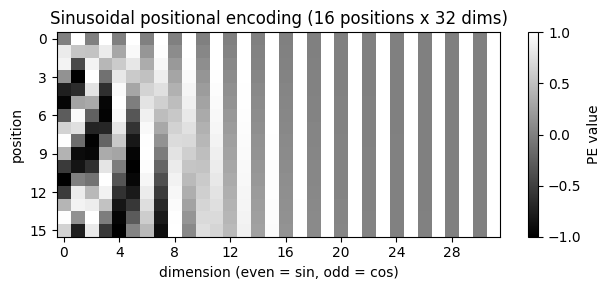

In [2]:
# ============ Plot 1 ============
import os
os.makedirs('../figures', exist_ok=True)
pe = lab07.positional_encoding(lab07.MAX_LEN, lab07.D_MODEL)[0]   # (16, 32)
fig, ax = plt.subplots(figsize=(6.4, 3.0))
im = ax.imshow(pe, aspect='auto', cmap='gray', vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label='PE value')
ax.set_xlabel('dimension (even = sin, odd = cos)')
ax.set_ylabel('position')
ax.set_xticks(range(0, lab07.D_MODEL, 4))
ax.set_yticks(range(0, lab07.MAX_LEN, 3))
ax.set_title('Sinusoidal positional encoding (16 positions x 32 dims)')
fig.tight_layout()
fig.savefig('../figures/fig1_positional_encoding.png', dpi=200)
plt.show()
# ================================

## Plot 2 — Attention weights for one log

The cell below retrains the `encoder_pos` configuration. It uses the same seed as
`run_experiment`, so it is the same model, and then reads the attention weights out of your
`EncoderBlock`. Nothing here is graded; the plot after it is.

In [3]:
lab07.set_seed(lab07.SEED)
model = lab07.SeqClassifier(use_attention=True, use_positional=True)
lab07.train_model(model, data)

i = 0                                        # try a few different logs
tokens, mask = data['x_val'][i:i + 1], data['mask_val'][i:i + 1]
model.eval()
with torch.no_grad():
    h = model.embed(tokens) + model.pe[:, :tokens.shape[1]]
    _, attn = model.encoder(h, mask[:, None, None, :])
attn = attn[0].mean(dim=0)                   # average the 4 heads -> (16, 16)

print('token ids      :', tokens[0].tolist())
print('real events    :', int(mask[0].sum()), 'of', mask.shape[1])
print('heat alarm at  :', (tokens[0] == 1).nonzero().item())
print('pressure at    :', (tokens[0] == 2).nonzero().item())
print('label          :', data['y_val'][i].item(), '(1 = heat first)')

token ids      : [5, 5, 2, 1, 6, 5, 3, 4, 0, 0, 0, 0, 0, 0, 0, 0]
real events    : 8 of 16
heat alarm at  : 3
pressure at    : 2
label          : 0.0 (1 = heat first)


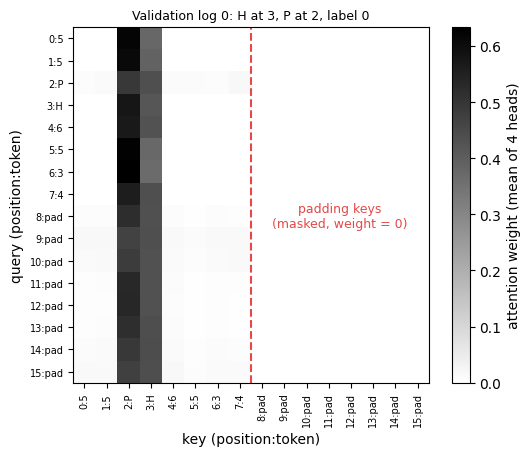

max weight on padded keys: 0.0
row sums (should be 1):    0.9999998807907104 1.0000001192092896


In [4]:
# ============ Plot 2 ============
n_real = int(mask[0].sum())
names = {0: 'pad', 1: 'H', 2: 'P'}
labels = [f'{p}:{names.get(t, t)}' for p, t in enumerate(tokens[0].tolist())]
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(attn, cmap='gray_r', vmin=0)
fig.colorbar(im, ax=ax, label='attention weight (mean of 4 heads)')
ax.set_xticks(range(lab07.MAX_LEN), labels, rotation=90, fontsize=7)
ax.set_yticks(range(lab07.MAX_LEN), labels, fontsize=7)
ax.set_xlabel('key (position:token)')
ax.set_ylabel('query (position:token)')
ax.axvline(n_real - 0.5, color='#e34948', ls='--', lw=1.5)
ax.text((n_real + lab07.MAX_LEN - 1) / 2, lab07.MAX_LEN / 2, 'padding keys\n(masked, weight = 0)', color='#e34948', ha='center', va='center', fontsize=9)
ax.set_title(f'Validation log {i}: H at {labels.index(next(l for l in labels if l.endswith(":H")))}, '
             f'P at {labels.index(next(l for l in labels if l.endswith(":P")))}, label {int(data["y_val"][i])}',
             fontsize=9)
fig.tight_layout()
fig.savefig('../figures/fig2_attention.png', dpi=200)
plt.show()
# The padded key columns must carry EXACTLY zero weight for every query (mask -> -inf before softmax).
print('max weight on padded keys:', attn[:, n_real:].max().item())
print('row sums (should be 1):   ', attn.sum(-1).min().item(), attn.sum(-1).max().item())
# ================================

## Plot 3 — The ablation

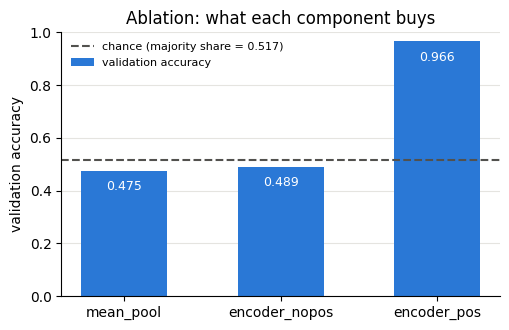

In [5]:
# ============ Plot 3 ============
names = list(results)
acc = [results[n]['accuracy'] for n in names]
chance = max(data['y_val'].mean().item(), 1 - data['y_val'].mean().item())
fig, ax = plt.subplots(figsize=(5.2, 3.4))
bars = ax.bar(names, acc, width=0.55, color='#2a78d6', label='validation accuracy')
ax.bar_label(bars, fmt='%.3f', padding=-16, fontsize=9, color='white')
ax.axhline(chance, color='#52514e', ls='--', lw=1.5, label=f'chance (majority share = {chance:.3f})')
ax.set_ylim(0, 1)
ax.set_ylabel('validation accuracy')
ax.set_title('Ablation: what each component buys')
ax.grid(axis='y', color='#e5e4e0', lw=0.8)
ax.set_axisbelow(True)
for s in ('top', 'right'):
    ax.spines[s].set_visible(False)
ax.legend(loc='upper left', fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig('../figures/fig3_ablation.png', dpi=200)
plt.show()
# ================================